# 2. Preprocessing and Lot-Aware Data Split

This notebook prepares the labeled WM-811K wafer maps for PyTorch training. It preserves the official lot-disjoint test set, creates lot-aware training and validation subsets, standardizes the input dimensions, and encodes the class labels.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open Jupyter from the "
        "'wafer-map-defect-classification' folder."
    )

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures"

PROCESSED_DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Processed data directory:", PROCESSED_DATA_DIR)

Project root: <LOCAL_PATH>
Processed data directory: <LOCAL_PATH>


## 2.1 Load and Filter the Labeled Dataset

In [2]:
from src.data_loading import load_wm811k


DATA_ARCHIVE = RAW_DATA_DIR / "WM811K_source.zip"

wm811k = load_wm811k(DATA_ARCHIVE)


def extract_label(value):
    """Convert nested list- or array-wrapped labels into plain strings."""

    while isinstance(value, (np.ndarray, list, tuple)):
        if len(value) == 0:
            return None
        value = value[0]

    return value


wm811k["split"] = wm811k["trianTestLabel"].apply(extract_label)
wm811k["failure_type"] = wm811k["failureType"].apply(extract_label)

labeled_data = wm811k[
    wm811k["failure_type"].notna()
].copy()

print("Full dataset shape:", wm811k.shape)
print("Labeled dataset shape:", labeled_data.shape)

print("\nOriginal split counts:")
print(labeled_data["split"].value_counts())

Full dataset shape: (811457, 8)
Labeled dataset shape: (172950, 8)

Original split counts:
split
Test        118595
Training     54355
Name: count, dtype: int64


In [7]:
SRC_DIR = PROJECT_ROOT / "src"
SRC_DIR.mkdir(exist_ok=True)

print("Source directory:", SRC_DIR)

Source directory: <LOCAL_PATH>


In [4]:
%%writefile ../src/data_loading.py

"""Compatibility helpers for loading the legacy WM-811K dataset."""

from pathlib import Path
import pickle
import zipfile


class LegacyPandasUnpickler(pickle.Unpickler):
    """Map old pandas module paths to their current locations."""

    def find_class(self, module, name):
        module = module.replace(
            "pandas.indexes",
            "pandas.core.indexes",
        )
        return super().find_class(module, name)


def load_wm811k(path):
    """Load LSWMD.pkl directly or from its original ZIP archive."""

    path = Path(path)

    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path, "r") as archive:
            pickle_files = [
                name
                for name in archive.namelist()
                if name.endswith(".pkl")
            ]

            if len(pickle_files) != 1:
                raise ValueError(
                    "The archive must contain exactly one pickle file."
                )

            with archive.open(pickle_files[0]) as file:
                return LegacyPandasUnpickler(
                    file,
                    encoding="latin1",
                ).load()

    with path.open("rb") as file:
        return LegacyPandasUnpickler(
            file,
            encoding="latin1",
        ).load()

Overwriting ../src/data_loading.py


## 2.2 Create Lot-Aware Training, Validation, and Test Sets

In [5]:
from sklearn.model_selection import StratifiedGroupKFold


CLASS_NAMES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
    "none",
]

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

labeled_data["label_index"] = labeled_data["failure_type"].map(
    class_to_index
)

official_training = labeled_data[
    labeled_data["split"] == "Training"
].copy()

test_data = labeled_data[
    labeled_data["split"] == "Test"
].copy()

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

train_positions, validation_positions = next(
    splitter.split(
        X=official_training,
        y=official_training["label_index"],
        groups=official_training["lotName"],
    )
)

train_data = official_training.iloc[train_positions].copy()
validation_data = official_training.iloc[validation_positions].copy()

train_lots = set(train_data["lotName"])
validation_lots = set(validation_data["lotName"])
test_lots = set(test_data["lotName"])

print("Training wafers:", len(train_data))
print("Validation wafers:", len(validation_data))
print("Test wafers:", len(test_data))

print("\nTraining/validation lot overlap:",
      len(train_lots.intersection(validation_lots)))

print("Training/test lot overlap:",
      len(train_lots.intersection(test_lots)))

print("Validation/test lot overlap:",
      len(validation_lots.intersection(test_lots)))

print("\nClass counts by final split:")

final_split_counts = pd.concat(
    {
        "Training": train_data["failure_type"].value_counts(),
        "Validation": validation_data["failure_type"].value_counts(),
        "Test": test_data["failure_type"].value_counts(),
    },
    axis=1,
).fillna(0).astype(int)

display(final_split_counts.loc[CLASS_NAMES])

Training wafers: 43486
Validation wafers: 10869
Test wafers: 118595

Training/validation lot overlap: 0
Training/test lot overlap: 0
Validation/test lot overlap: 0

Class counts by final split:


,Training,Validation,Test
failure_type,,,
Center,2769,693,832
Donut,327,82,146
Edge-Loc,1934,483,2772
Edge-Ring,6843,1711,1126
Loc,1296,324,1973
Near-full,44,10,95
Random,487,122,257
Scratch,400,100,693
none,29386,7344,110701


## 2.3 Standardize Wafer Maps for CNN Input

Original map shape: (26, 26)
Processed tensor shape: torch.Size([1, 64, 64])
Processed values: tensor([0.0000, 0.5000, 1.0000])


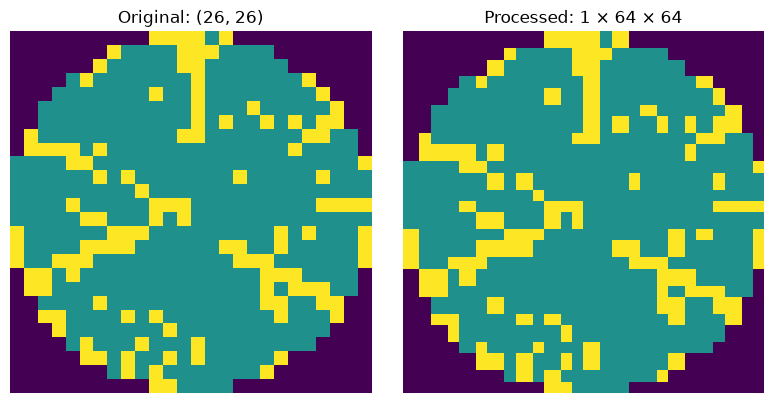

In [11]:
import torch
import torch.nn.functional as F


TARGET_SIZE = 64


def preprocess_wafer_map(wafer_map, target_size=TARGET_SIZE):
    """Pad, resize, normalize, and convert a wafer map to a PyTorch tensor."""

    wafer_map = np.asarray(wafer_map, dtype=np.float32)

    height, width = wafer_map.shape
    square_size = max(height, width)

    padded_map = np.zeros(
        (square_size, square_size),
        dtype=np.float32,
    )

    top = (square_size - height) // 2
    left = (square_size - width) // 2

    padded_map[
        top:top + height,
        left:left + width,
    ] = wafer_map

    tensor = torch.from_numpy(padded_map)
    tensor = tensor.unsqueeze(0).unsqueeze(0)

    resized_tensor = F.interpolate(
        tensor,
        size=(target_size, target_size),
        mode="nearest",
    )

    normalized_tensor = resized_tensor.squeeze(0) / 2.0

    return normalized_tensor

example_row = train_data[
    train_data["failure_type"] == "Scratch"
].iloc[0]

original_map = example_row["waferMap"]
processed_tensor = preprocess_wafer_map(original_map)

print("Original map shape:", original_map.shape)
print("Processed tensor shape:", processed_tensor.shape)
print("Processed values:", torch.unique(processed_tensor))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_map, cmap="viridis", vmin=0, vmax=2)
axes[0].set_title(f"Original: {original_map.shape}")
axes[0].axis("off")

axes[1].imshow(
    processed_tensor.squeeze(0),
    cmap="viridis",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Processed: 1 × 64 × 64")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
import torch
import torch.nn.functional as F

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch version: 2.14.1
MPS available: True


Original rectangular shape: (45, 48)
Processed tensor shape: torch.Size([1, 64, 64])
Processed values: tensor([0.0000, 0.5000, 1.0000])


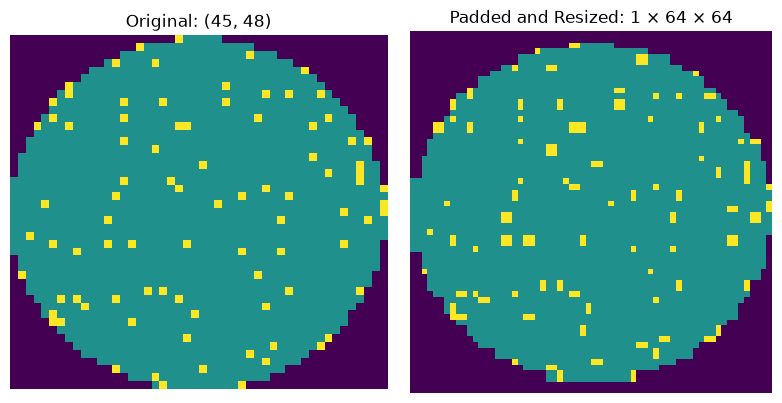

In [12]:
rectangular_row = train_data[
    train_data["waferMap"].apply(
        lambda wafer_map: wafer_map.shape[0] != wafer_map.shape[1]
    )
].iloc[0]

rectangular_map = rectangular_row["waferMap"]
rectangular_tensor = preprocess_wafer_map(rectangular_map)

print("Original rectangular shape:", rectangular_map.shape)
print("Processed tensor shape:", rectangular_tensor.shape)
print("Processed values:", torch.unique(rectangular_tensor))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(
    rectangular_map,
    cmap="viridis",
    vmin=0,
    vmax=2,
)
axes[0].set_title(f"Original: {rectangular_map.shape}")
axes[0].axis("off")

axes[1].imshow(
    rectangular_tensor.squeeze(0),
    cmap="viridis",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Padded and Resized: 1 × 64 × 64")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [13]:
%%writefile ../src/preprocessing.py

"""Preprocessing utilities for WM-811K wafer maps."""

import numpy as np
import torch
import torch.nn.functional as F


TARGET_SIZE = 64


def preprocess_wafer_map(wafer_map, target_size=TARGET_SIZE):
    """Pad, resize, normalize, and convert a wafer map to a tensor."""

    wafer_map = np.asarray(wafer_map, dtype=np.float32)

    height, width = wafer_map.shape
    square_size = max(height, width)

    padded_map = np.zeros(
        (square_size, square_size),
        dtype=np.float32,
    )

    top = (square_size - height) // 2
    left = (square_size - width) // 2

    padded_map[
        top:top + height,
        left:left + width,
    ] = wafer_map

    tensor = torch.from_numpy(padded_map)
    tensor = tensor.unsqueeze(0).unsqueeze(0)

    resized_tensor = F.interpolate(
        tensor,
        size=(target_size, target_size),
        mode="nearest",
    )

    normalized_tensor = resized_tensor.squeeze(0) / 2.0

    return normalized_tensor

Writing ../src/preprocessing.py


## 2.4 Save Split Manifests

In [14]:
import json


def create_manifest(data, split_name):
    """Create a lightweight manifest without duplicating wafer-map arrays."""

    manifest = data[
        [
            "lotName",
            "waferIndex",
            "failure_type",
            "label_index",
        ]
    ].copy()

    manifest.insert(0, "source_index", data.index)
    manifest.insert(1, "dataset_split", split_name)

    return manifest.reset_index(drop=True)


train_manifest = create_manifest(train_data, "train")
validation_manifest = create_manifest(validation_data, "validation")
test_manifest = create_manifest(test_data, "test")

train_manifest.to_csv(
    PROCESSED_DATA_DIR / "train_manifest.csv",
    index=False,
)

validation_manifest.to_csv(
    PROCESSED_DATA_DIR / "validation_manifest.csv",
    index=False,
)

test_manifest.to_csv(
    PROCESSED_DATA_DIR / "test_manifest.csv",
    index=False,
)

with open(
    PROCESSED_DATA_DIR / "class_mapping.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(class_to_index, file, indent=2)

print("Training manifest:", train_manifest.shape)
print("Validation manifest:", validation_manifest.shape)
print("Test manifest:", test_manifest.shape)

print("\nSaved files:")
for path in sorted(PROCESSED_DATA_DIR.iterdir()):
    if not path.name.startswith("."):
        print("-", path.name)

Training manifest: (43486, 6)
Validation manifest: (10869, 6)
Test manifest: (118595, 6)

Saved files:
- class_mapping.json
- test_manifest.csv
- train_manifest.csv
- validation_manifest.csv


## 2.5 Validate the Saved Manifests

In [15]:
saved_train = pd.read_csv(
    PROCESSED_DATA_DIR / "train_manifest.csv"
)

saved_validation = pd.read_csv(
    PROCESSED_DATA_DIR / "validation_manifest.csv"
)

saved_test = pd.read_csv(
    PROCESSED_DATA_DIR / "test_manifest.csv"
)

assert len(saved_train) == len(train_data)
assert len(saved_validation) == len(validation_data)
assert len(saved_test) == len(test_data)

assert set(saved_train["source_index"]).isdisjoint(
    set(saved_validation["source_index"])
)

assert set(saved_train["source_index"]).isdisjoint(
    set(saved_test["source_index"])
)

assert set(saved_validation["source_index"]).isdisjoint(
    set(saved_test["source_index"])
)

assert set(saved_train["lotName"]).isdisjoint(
    set(saved_validation["lotName"])
)

assert set(saved_train["lotName"]).isdisjoint(
    set(saved_test["lotName"])
)

assert set(saved_validation["lotName"]).isdisjoint(
    set(saved_test["lotName"])
)

assert set(saved_train["label_index"]).issubset(
    set(range(len(CLASS_NAMES)))
)

print("All manifest validation checks passed.")

All manifest validation checks passed.


## 2.6 Preprocessing Summary

- The official lot-disjoint test set was preserved for final evaluation.
- The official training subset was divided into training and validation subsets using `StratifiedGroupKFold`.
- No wafer records or lots overlap across the training, validation, and test subsets.
- Each wafer map is padded to a square, resized to 64 × 64 using nearest-neighbor interpolation, normalized to the range 0–1, and represented as a single-channel PyTorch tensor.
- Lightweight CSV manifests store the source row, lot, wafer index, class name, and numeric label without duplicating the original wafer-map arrays.
- The next stage will build PyTorch `Dataset` and `DataLoader` objects and train a small CNN.